# Telecom Customer Churn Analysis

> Run the notebook from top to bottom. Update the input file path if your dataset is stored elsewhere.


## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load and inspect the data

In [ ]:
# Load cleaned telecom customer data
df = pd.read_csv(
    'telecom_clean_data.csv'
)

# Inspect dataset structure, missing values and duplicates
print("Dataset shape:", df.shape)
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (7043, 22)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        7043 non-null   str    
 1   Gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   Tenure            7043 non-null   int64  
 6   TenureGroup       7043 non-null   str    
 7   PhoneService      7043 non-null   str    
 8   MultipleLines     7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  Contract          7043 non-

## 3. Overall churn and revenue analysis

In [3]:
# Create binary churn indicator (1 = Churned, 0 = Retained)
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)

# Calculate overall customer churn rate
overall_churn = df['ChurnFlag'].mean() * 100
print(f"Overall Churn Rate: {overall_churn:.2f}%")

# Calculate monthly charges associated with churned customers
churned_monthly_revenue = df.loc[df['ChurnFlag'] == 1, 'MonthlyCharges'].sum()
total_monthly_revenue = df['MonthlyCharges'].sum()

# Calculate the share of total monthly charges associated with churn
revenue_at_risk_pct = (
    churned_monthly_revenue / total_monthly_revenue * 100
    if total_monthly_revenue else 0
)

print(f"Monthly Charges Associated With Churn: ${churned_monthly_revenue:,.2f}")
print(f"Share of Total Monthly Charges: {revenue_at_risk_pct:.2f}%")

# Identify monthly charges associated with churn across contract types
contract_revenue = (
    df.loc[df['ChurnFlag'] == 1]
      .groupby('Contract')['MonthlyCharges']
      .sum()
)
print("\nMonthly Charges Associated With Churn By Contract:")
print(contract_revenue)

Overall Churn Rate: 26.54%
Monthly Charges Associated With Churn: $139,130.85
Share of Total Monthly Charges: 30.50%

Monthly Charges Associated With Churn By Contract:
Contract
Month-to-month    120847.10
One year           14118.45
Two year            4165.30
Name: MonthlyCharges, dtype: float64


## 4. Identify and analyse a high-risk customer segment

In [4]:
# Identify customers with the selected combination of churn risk factors
mask = (
    (df['Contract'] == 'Month-to-month') &
    (df['PaymentMethod'] == 'Electronic check') &
    (df['InternetService'] == 'Fiber optic')
)

segment = df.loc[mask].copy()

# Calculate churn rate and monthly charges associated with churn in this segment
segment_churn = segment['ChurnFlag'].mean() * 100
segment_revenue = segment.loc[segment['ChurnFlag'] == 1, 'MonthlyCharges'].sum()

segment_revenue_share = (
    segment_revenue / churned_monthly_revenue * 100
    if churned_monthly_revenue else 0
)

print(f"High-Risk Segment Customers: {len(segment):,}")
print(f"Segment Churn Rate: {segment_churn:.2f}%")
print(f"Share of Churn-Related Monthly Charges: {segment_revenue_share:.2f}%")

# Classify customers for segment-level comparison
df['Segment'] = 'All Other Customers'
df.loc[mask, 'Segment'] = 'High-Risk Customers'

High-Risk Segment Customers: 1,307
Segment Churn Rate: 60.37%
Share of Churn-Related Monthly Charges: 49.08%


## 5. Churn analysis across customer attributes

In [5]:
# Define customer attributes for individual churn analysis
cols = [
    'Contract',
    'TenureGroup',
    'InternetService',
    'PaymentMethod',
    'TechSupport',
    'PaperlessBilling'
]

# Compare churn rates across selected customer attributes
for col in cols:
    print(f"\nChurn Rate By {col}:")
    print((df.groupby(col)['ChurnFlag'].mean() * 100).round(2))


Churn Rate By Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64

Churn Rate By TenureGroup:
TenureGroup
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49+ Months       9.51
Name: ChurnFlag, dtype: float64

Churn Rate By InternetService:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: ChurnFlag, dtype: float64

Churn Rate By PaymentMethod:
PaymentMethod
Bank transfer       16.71
Credit card         15.24
Electronic check    45.29
Mailed check        19.11
Name: ChurnFlag, dtype: float64

Churn Rate By TechSupport:
TechSupport
No     31.19
Yes    15.17
Name: ChurnFlag, dtype: float64

Churn Rate By PaperlessBilling:
PaperlessBilling
No     16.33
Yes    33.57
Name: ChurnFlag, dtype: float64


In [6]:
# Compare average tenure and monthly charges by churn status
churn_summary = pd.pivot_table(
    df,
    values=['Tenure', 'MonthlyCharges'],
    index='Churn',
    aggfunc='mean'
)

print(churn_summary)

# Analyse monthly charges associated with churn across tenure groups
tenure_revenue = (
    df.loc[df['ChurnFlag'] == 1]
      .groupby('TenureGroup')['MonthlyCharges']
      .sum()
)

print("\nMonthly Charges Associated With Churn By Tenure Group:")
print(tenure_revenue)

# Analyse tech support and churn among internet service customers
df1 = df.loc[df['InternetService'] != 'No'].copy()

tech_support_churn = df1.groupby('TechSupport')['ChurnFlag'].mean() * 100
print("\nChurn Rate By Tech Support (Internet Customers):")
print(tech_support_churn.round(2))

       MonthlyCharges     Tenure
Churn                           
No          61.265124  37.569965
Yes         74.441332  17.979133

Monthly Charges Associated With Churn By Tenure Group:
TenureGroup
0-12 Months     68954.25
13-24 Months    23081.65
25-48 Months    27462.50
49+ Months      19632.45
Name: MonthlyCharges, dtype: float64

Churn Rate By Tech Support (Internet Customers):
TechSupport
No     41.64
Yes    15.17
Name: ChurnFlag, dtype: float64


## 6. Visualise churn patterns

### 6.1 Reusable bar chart function

In [25]:
# Reusable function to plot and save churn rate comparisons
def plot_churn(data, column, title, order=None):
    plt.figure(figsize=(8, 5))

    ax = sns.barplot(
        data=data,
        x=column,
        y='ChurnFlag',
        errorbar=None,
        order=order
    )

    # Display churn rates as percentages
    for container in ax.containers:
        labels = [f'{value * 100:.1f}%' for value in container.datavalues]
        ax.bar_label(container, labels=labels, padding=1)

    plt.title(title)
    plt.xlabel(column)
    plt.ylabel('Churn Rate (%)')
    plt.tight_layout()
    plt.show()

### 6.2 Churn by contract type

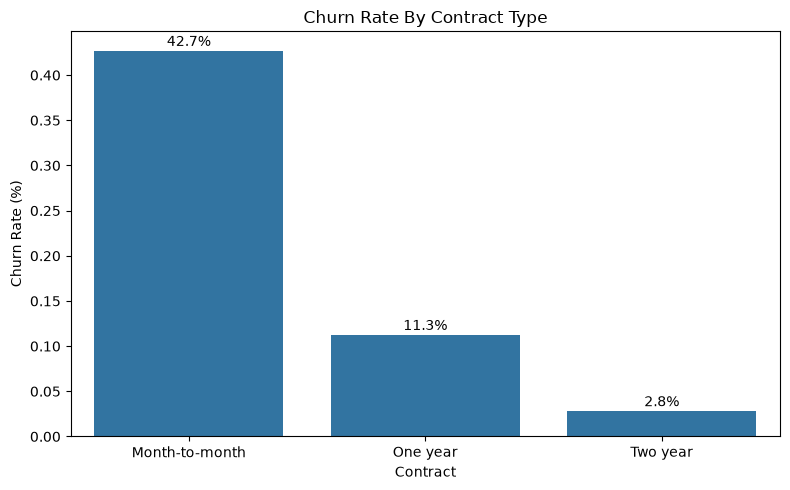

In [26]:
plot_churn(
    df,
    'Contract',
    'Churn Rate By Contract Type'
)

### 6.3 Tenure distribution by churn status

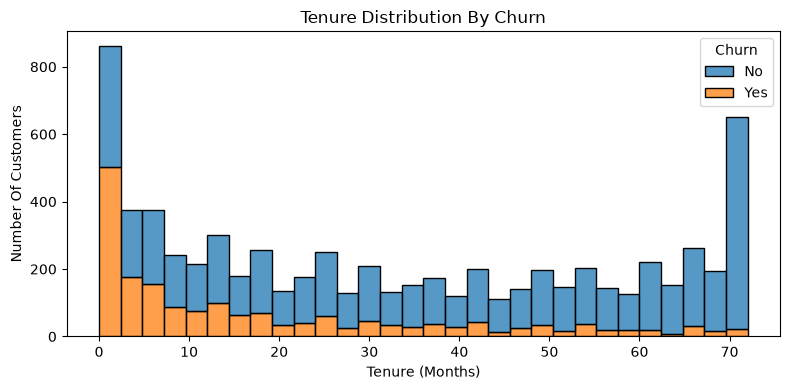

In [ ]:
# Compare customer tenure distribution by churn status
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Tenure', hue='Churn', bins=30, multiple='stack')
plt.title('Tenure Distribution By Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number Of Customers')
plt.tight_layout()
plt.show()

ax.barlabel(ax.cou)

### 6.4 Monthly charges by churn status

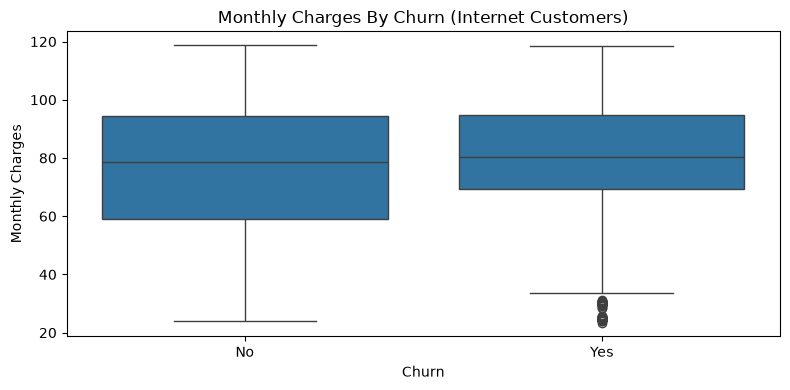

In [ ]:
# Compare monthly charges between churned and retained internet customers
plt.figure(figsize=(8, 4))
sns.boxplot(data=df1, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges By Churn (Internet Customers)')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.show()

### 6.5 Churn by internet service

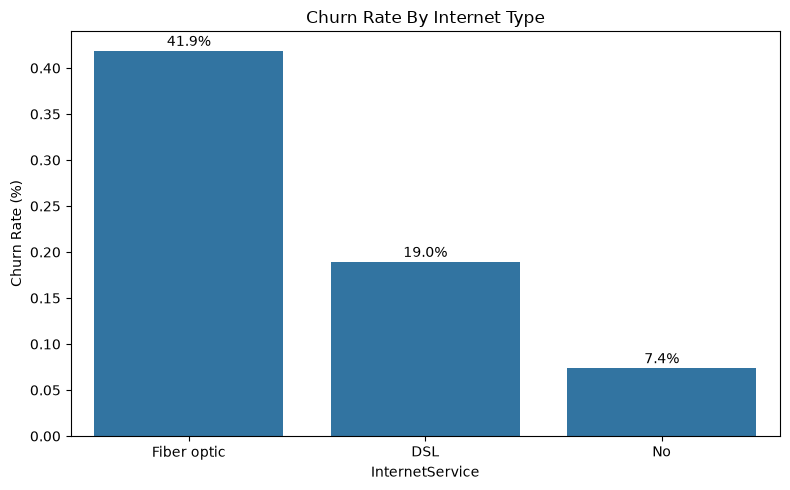

In [27]:
plot_churn(
    df,
    'InternetService',
    'Churn Rate By Internet Type',
    order=['Fiber optic', 'DSL', 'No']
)

### 6.6 Churn by payment method

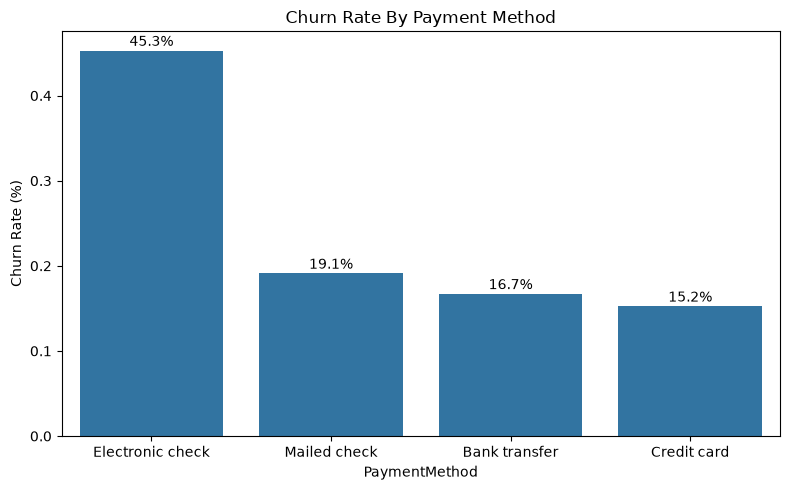

In [12]:
plot_churn(
    df,
    'PaymentMethod',
    'Churn Rate By Payment Method'
)

### 6.7 Churn by tech support

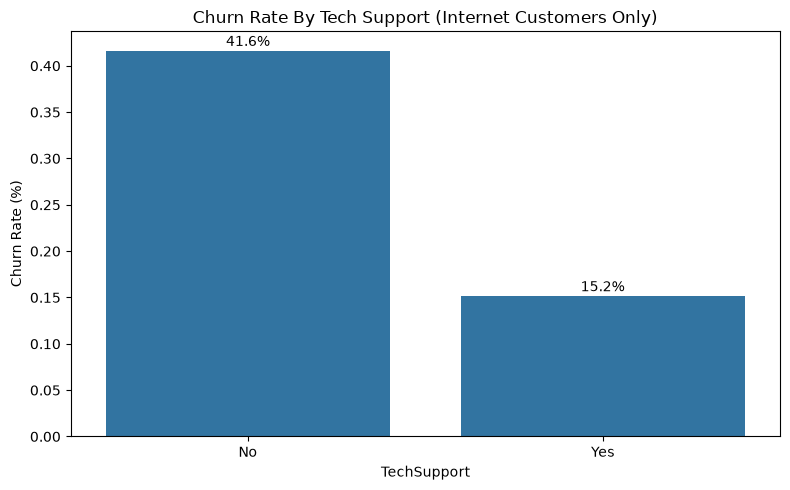

In [13]:
plot_churn(
    df1,
    'TechSupport',
    'Churn Rate By Tech Support (Internet Customers Only)'
)

### 6.8 High-risk segment versus other customers

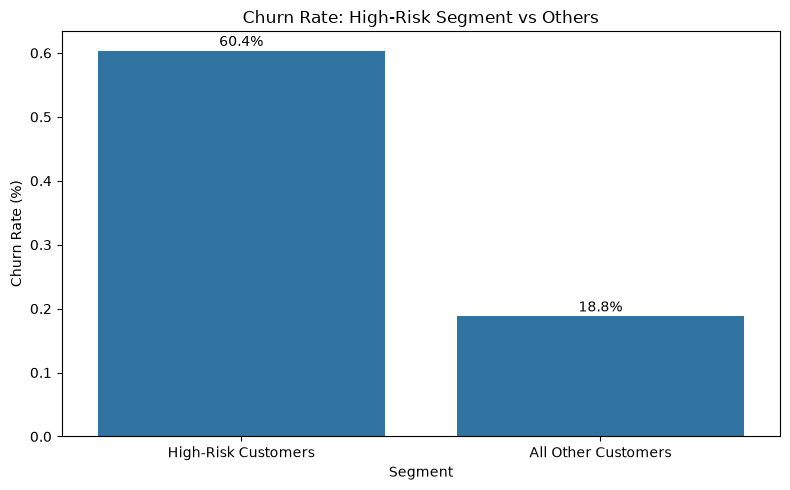

In [14]:
plot_churn(
    df,
    'Segment',
    'Churn Rate: High-Risk Segment vs Others',
    order=['High-Risk Customers', 'All Other Customers']
)

## 7. Correlation analysis

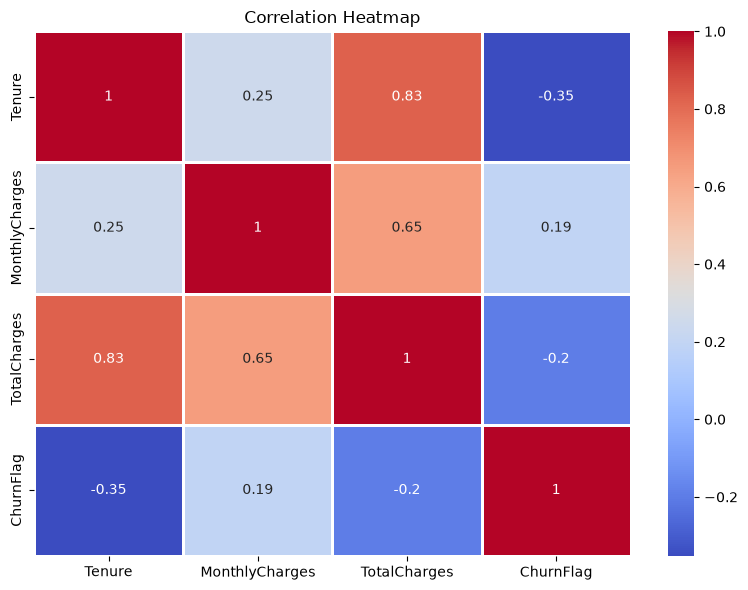

In [15]:
# Examine correlations between tenure, charges and customer churn
df_matrix = df[['Tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']]
corr_matrix = df_matrix.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    linecolor='white',
    linewidths=1,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [17]:
# Calculate churn rates and 95% Wilson confidence intervals by customer segment
from statsmodels.stats.proportion import proportion_confint

# Calculate churned customers and total customers in each segment
seg = df.groupby('Segment')['ChurnFlag'].agg(
    churned='sum',
    customers='count'
)

# Calculate observed churn rate (%)
seg['churn_pct'] = seg['churned'] / seg['customers'] * 100

# Calculate 95% Wilson confidence intervals for churn rates
low, high = proportion_confint(
    seg['churned'],
    seg['customers'],
    method='wilson',
    alpha=0.05
)

# Convert confidence interval bounds to percentages
seg['low_%'] = low * 100
seg['high_%'] = high * 100

# Display segment-level churn rates and confidence intervals
print(seg.round(1))


                     churned  customers  churn_pct  low_%  high_%
Segment                                                          
All Other Customers     1080       5736       18.8   17.8    19.9
High-Risk Customers      789       1307       60.4   57.7    63.0


In [18]:
# Chi-Square Test & Cramér's V

from scipy.stats import chi2_contingency

# Create contingency table of customer segment vs churn status
table = pd.crosstab(df['Segment'], df['Churn'])

# Test for association between segment and churn
chi2, p, dof, expected = chi2_contingency(table)

# Calculate Cramér's V to measure association strength
n = table.to_numpy().sum()
k = min(table.shape) - 1

cramers_v = (chi2 / (n * k)) ** 0.5

# Store statistical test results
results = [{
    'chi2_statistic': round(chi2, 2),
    'p_value': p,
    'degrees_of_freedom': dof,
    'cramers_v': round(cramers_v, 3)
}]

results_df = pd.DataFrame(results)
print(results_df.round(3))


   chi2_statistic  p_value  degrees_of_freedom  cramers_v
0          940.01      0.0                   1      0.365


## 8. Export data for Power BI

In [19]:
# Export analysed customer data for Power BI dashboard development
df.to_csv('Telco_Churn_Dashboard.csv', index=False)

print("Export complete: Telco_Churn_Dashboard.csv")

Export complete: Telco_Churn_Dashboard.csv
